In [1]:
import pandas as pd

df = pd.read_csv("data/ames_housing.csv")

In [2]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

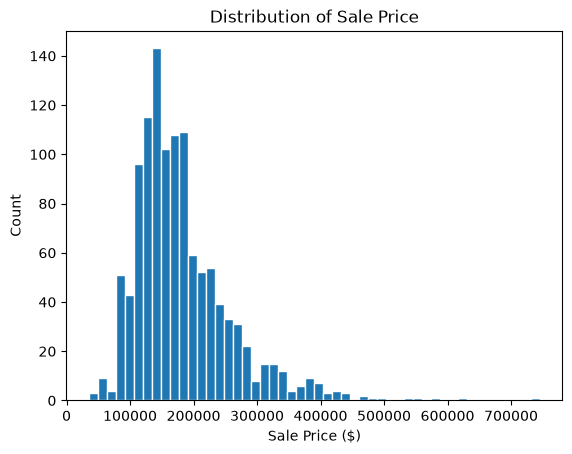

In [8]:
import matplotlib.pyplot as plt

plt.hist(train_df['SalePrice'], bins=50, edgecolor='white')
plt.xlabel("Sale Price ($)")
plt.ylabel("Count")
plt.title("Distribution of Sale Price")
plt.show()

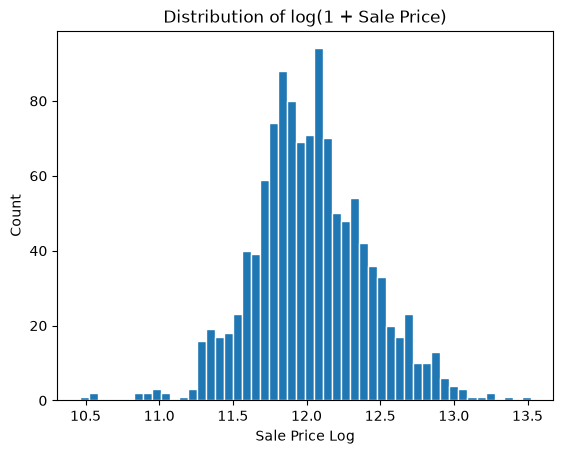

In [11]:
import numpy as np


plt.hist(np.log1p(train_df['SalePrice']), bins=50, edgecolor='white')
plt.xlabel("Sale Price Log")
plt.ylabel("Count")
plt.title("Distribution of log(1 + Sale Price)")
plt.show()

In [12]:
print(train_df['SalePrice'].mean())
print(train_df['SalePrice'].median())

181441.5419520548
165000.0


In [18]:
train_df.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False).head(20)

SalePrice       1.000000
OverallQual     0.785555
GrLivArea       0.695652
GarageCars      0.640991
GarageArea      0.624139
TotalBsmtSF     0.597766
1stFlrSF        0.587883
FullBath        0.552546
TotRmsAbvGrd    0.520388
YearBuilt       0.516501
YearRemodAdd    0.508593
GarageYrBlt     0.480351
MasVnrArea      0.459123
Fireplaces      0.457549
BsmtFinSF1      0.359460
LotFrontage     0.330066
WoodDeckSF      0.329843
2ndFlrSF        0.314030
OpenPorchSF     0.299969
HalfBath        0.280481
Name: SalePrice, dtype: float64

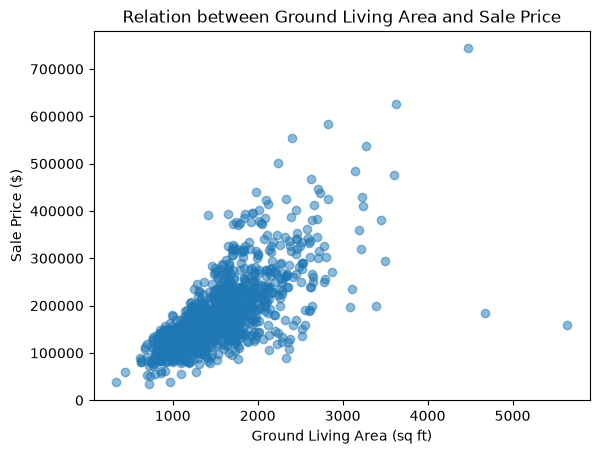

In [22]:
plt.scatter(train_df['GrLivArea'], train_df['SalePrice'], alpha=0.5)
plt.xlabel("Ground Living Area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.title("Relation between Ground Living Area and Sale Price")
plt.show()

In [25]:
train_df[train_df['GrLivArea']>4000][['GrLivArea','SalePrice', 'OverallQual', 'SaleCondition']]


,GrLivArea,SalePrice,OverallQual,SaleCondition
1182,4476,745000,10,Abnorml
523,4676,184750,10,Partial
1298,5642,160000,10,Partial


## Observations

1. **Target:** `SalePrice` is right-skewed. Most houses sell between $100,000 and $200,000, with a long tail of expensive ones. The mean ($181,442) is higher than the median ($165,000) because those few expensive houses pull it up. After a `log1p` transform the distribution is much more symmetric, which usually helps linear models.

2. **Features:** the numeric features most correlated with `SalePrice` are `OverallQual` (0.79), `GrLivArea` (0.70), `GarageCars` (0.64), `GarageArea` (0.62) and `TotalBsmtSF` (0.60). Caution: some of these measure almost the same thing (`GarageCars` and `GarageArea`, `TotalBsmtSF` and `1stFlrSF`), so they are high partly because they track each other. Correlation also only captures straight-line relationships.

3. **Unusual houses:** three houses have a living area above 4,000 sq ft, all with top quality (`OverallQual` 10). House 1182 sold for $745,000, which fits the trend (though its sale was `Abnorml`). Houses 523 and 1298 are `Partial` sales, so they were probably unfinished, and sold for only $184,750 and $160,000 despite being the largest. Left in the training data, they would pull a linear model's line down for big houses.

In [33]:
train_df.select_dtypes(exclude='number').nunique().sort_values(ascending=False).head(10)

Neighborhood    25
Exterior2nd     16
Exterior1st     15
SaleType         9
Condition1       9
Condition2       8
HouseStyle       8
Functional       7
RoofMatl         7
BsmtFinType2     6
dtype: int64

In [35]:
train_df['Neighborhood'].value_counts().tail(8)

Neighborhood
StoneBr    20
ClearCr    19
Blmngtn    15
BrDale     13
MeadowV    10
Veenker     9
NPkVill     7
Blueste     1
Name: count, dtype: int64

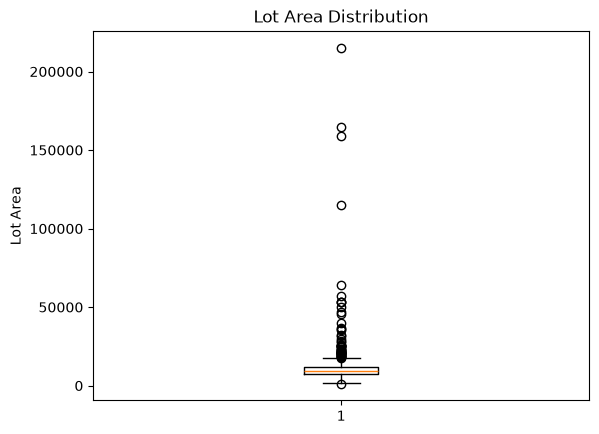

In [36]:
plt.boxplot(train_df['LotArea'])
plt.ylabel("Lot Area")
plt.title("Lot Area Distribution")
plt.show()

In [37]:
train_df['LotArea'].describe()

count      1168.000000
mean      10689.642123
std       10759.366198
min        1300.000000
25%        7587.250000
50%        9600.000000
75%       11700.000000
max      215245.000000
Name: LotArea, dtype: float64

In [41]:
train_df.sort_values('LotArea', ascending=False).head(5)[['LotArea', 'SalePrice', 'GrLivArea', 'Neighborhood']]

,LotArea,SalePrice,GrLivArea,Neighborhood
313,215245,375000,2036,Timber
335,164660,228950,1786,Timber
249,159000,277000,2144,ClearCr
706,115149,302000,1824,ClearCr
1298,63887,160000,5642,Edwards


## Cleaning decisions

1. **Blank means "feature doesn't exist"** (garage columns, checked: `GarageArea` is 0 for all 81 blanks): fill with the category "None". Still to verify the same way: pool, alley, fence, fireplace, basement and `MiscFeature`.
2. **Truly missing numbers** (`LotFrontage`, `MasVnrArea`): fill with the median. `GarageYrBlt` is blank because there is no garage, so it needs its own decision.
3. **Rare categories:** group neighborhoods with fewer than ~20 houses into "Other" (`min_frequency` in `OneHotEncoder`).
4. **Unseen categories:** use `handle_unknown="ignore"` in the encoder so a category only in the test set doesn't crash it.
5. **Target:** `log1p(SalePrice)`, since the log made it symmetric.
6. **Drop `Id`:** it's a row number with no information about the house.
7. **Check `MSSubClass`:** it's a code stored as a number, so it may need to be treated as a category.
8. **Houses 523 and 1298** (above 4,000 sq ft, `Partial` sales, low prices): decision pending, needs a written reason.
9. **Near-duplicate columns** (`GarageCars`/`GarageArea`, `TotalBsmtSF`/`1stFlrSF`): keep in mind when interpreting feature importance.
10. **`LotArea` outliers** (max 215,245 sq ft): keep the rows, because the prices are consistent with the houses. Log-transform `LotArea` for scale-sensitive models.